In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

In [4]:
df = pd.read_csv('C:/Users/sathw/Downloads/mlproject/src/notebook/data/stud.csv')
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [5]:
df.shape

(1000, 8)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race_ethnicity               1000 non-null   str  
 2   parental_level_of_education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test_preparation_course      1000 non-null   str  
 5   math_score                   1000 non-null   int64
 6   reading_score                1000 non-null   int64
 7   writing_score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [7]:
df.describe()

,math_score,reading_score,writing_score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [11]:
for i in df.columns:
    if df[i].dtype == 'str':
        print(i)
        print(df[i].unique())
        print(df[i].value_counts())
        print(df[i].nunique())
        print('-----------------------------------')

gender
<StringArray>
['female', 'male']
Length: 2, dtype: str
gender
female    518
male      482
Name: count, dtype: int64
2
-----------------------------------
race_ethnicity
<StringArray>
['group B', 'group C', 'group A', 'group D', 'group E']
Length: 5, dtype: str
race_ethnicity
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64
5
-----------------------------------
parental_level_of_education
<StringArray>
[ 'bachelor's degree',       'some college',    'master's degree',
 'associate's degree',        'high school',   'some high school']
Length: 6, dtype: str
parental_level_of_education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64
6
-----------------------------------
lunch
<StringArray>
['standard', 'free/reduced']
Length: 2, dtype: str
lunch
standard        645
free/reduced    355
Name: count, dt

In [12]:
df.isna().sum()

gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(0)

In [25]:
df=df.astype(
    {'gender' : 'object', 
    'race_ethnicity' : 'object', 
    'parental_level_of_education' : 'object', 
    'lunch' : 'object', 
    'test_preparation_course' : 'object'}
)
print(df.dtypes)

gender                         object
race_ethnicity                 object
parental_level_of_education    object
lunch                          object
test_preparation_course        object
math_score                      int64
reading_score                   int64
writing_score                   int64
dtype: object


In [28]:
numerical_features = [i for i in df.columns if df[i].dtype != 'object']
categorical_features = [i for i in df.columns if df[i].dtype == 'object']

print("Numerical Features:", numerical_features)
print(" we have {} numerical features and {} categorical features".format(len(numerical_features), len(categorical_features)))
print("Categorical Features:", categorical_features)

Numerical Features: ['math_score', 'reading_score', 'writing_score']
 we have 3 numerical features and 5 categorical features
Categorical Features: ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course']


In [29]:
df['total_score'] = df['math_score'] + df['reading_score'] + df['writing_score']
df['average'] = df['total_score'] / 3

In [30]:
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total_score,average
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333
4,male,group C,some college,standard,none,76,78,75,229,76.333333


In [31]:
reading_full = df[df['reading_score'] == 100]['average'].count()
math_full = df[df['math_score'] == 100]['average'].count()
writing_full = df[df['writing_score'] == 100]['average'].count()

print(f"Number of students with full marks in reading: {reading_full}")
print(f"Number of students with full marks in math: {math_full}")
print(f"Number of students with full marks in writing: {writing_full}")

Number of students with full marks in reading: 17
Number of students with full marks in math: 7
Number of students with full marks in writing: 14


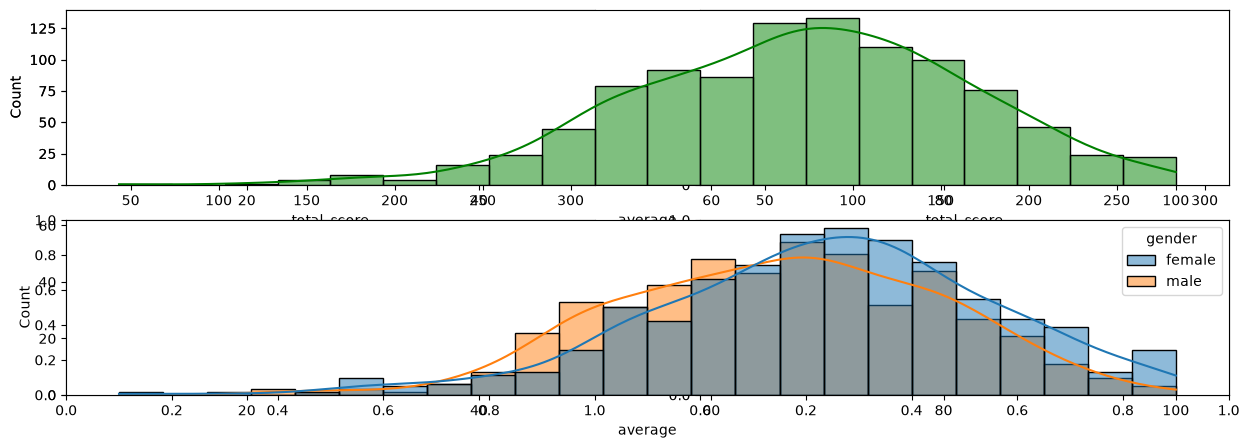

In [41]:
fig, axes = plt.subplots(2,2, figsize=(15,5))
plt.subplot(2,1,1)
sns.histplot(data=df,x='average',bins=20,kde=True,color='g')
plt.subplot(2,1,2)
sns.histplot(data=df,x='average',hue='gender',kde=True)
plt.subplot(2,2,1)
sns.histplot(data=df,x='total_score',bins=20,kde=True,color='g')
plt.subplot(2,2,2)
sns.histplot(data=df,x='total_score',hue='gender',kde=True)
plt.show()

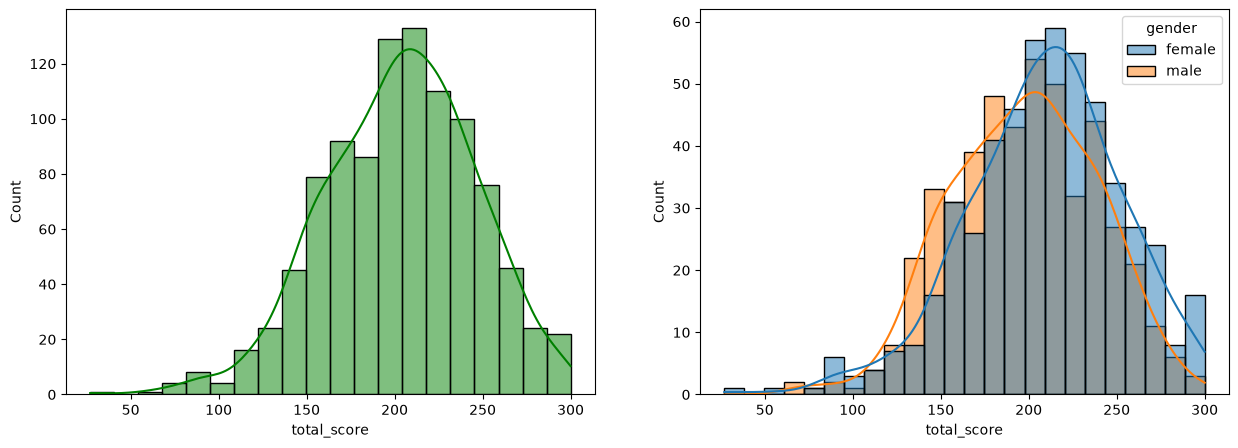

In [37]:
fig, axes = plt.subplots(1,2,figsize=(15,5))
plt.subplot(121)
sns.histplot(data=df,x='total_score',bins=20,kde=True,color='g')
plt.subplot(122)
sns.histplot(data=df,x='total_score',hue='gender',kde=True)
plt.show()

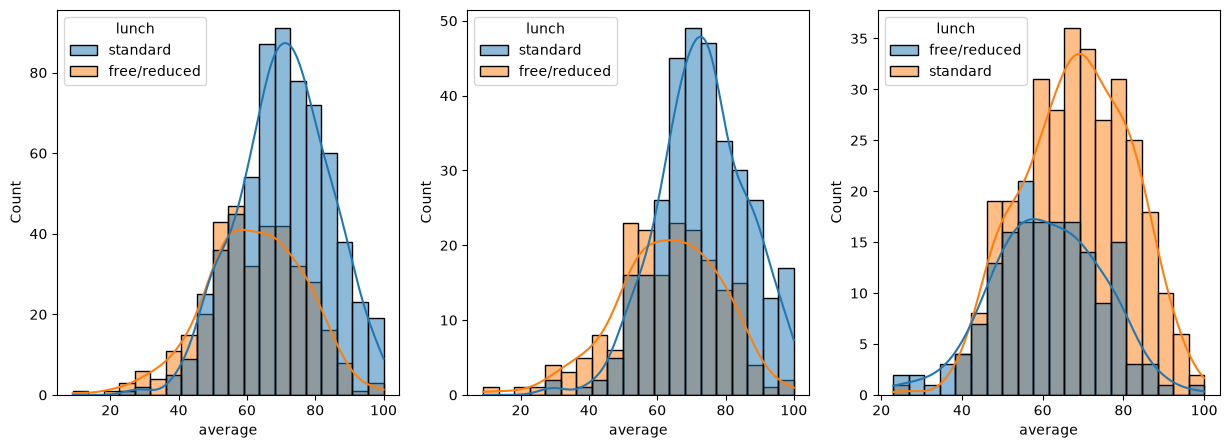

In [43]:
fig, axes = plt.subplots(1,3,figsize=(15,5))
plt.subplot(131)
sns.histplot(data=df,x='average',bins=20,kde=True,hue='lunch')
plt.subplot(132)
sns.histplot(data=df[df['gender']=='female'],x='average',bins=20,kde=True,hue='lunch')
plt.subplot(133)
sns.histplot(data=df[df['gender']=='male'],x='average',bins=20,kde=True,hue='lunch')
plt.show()

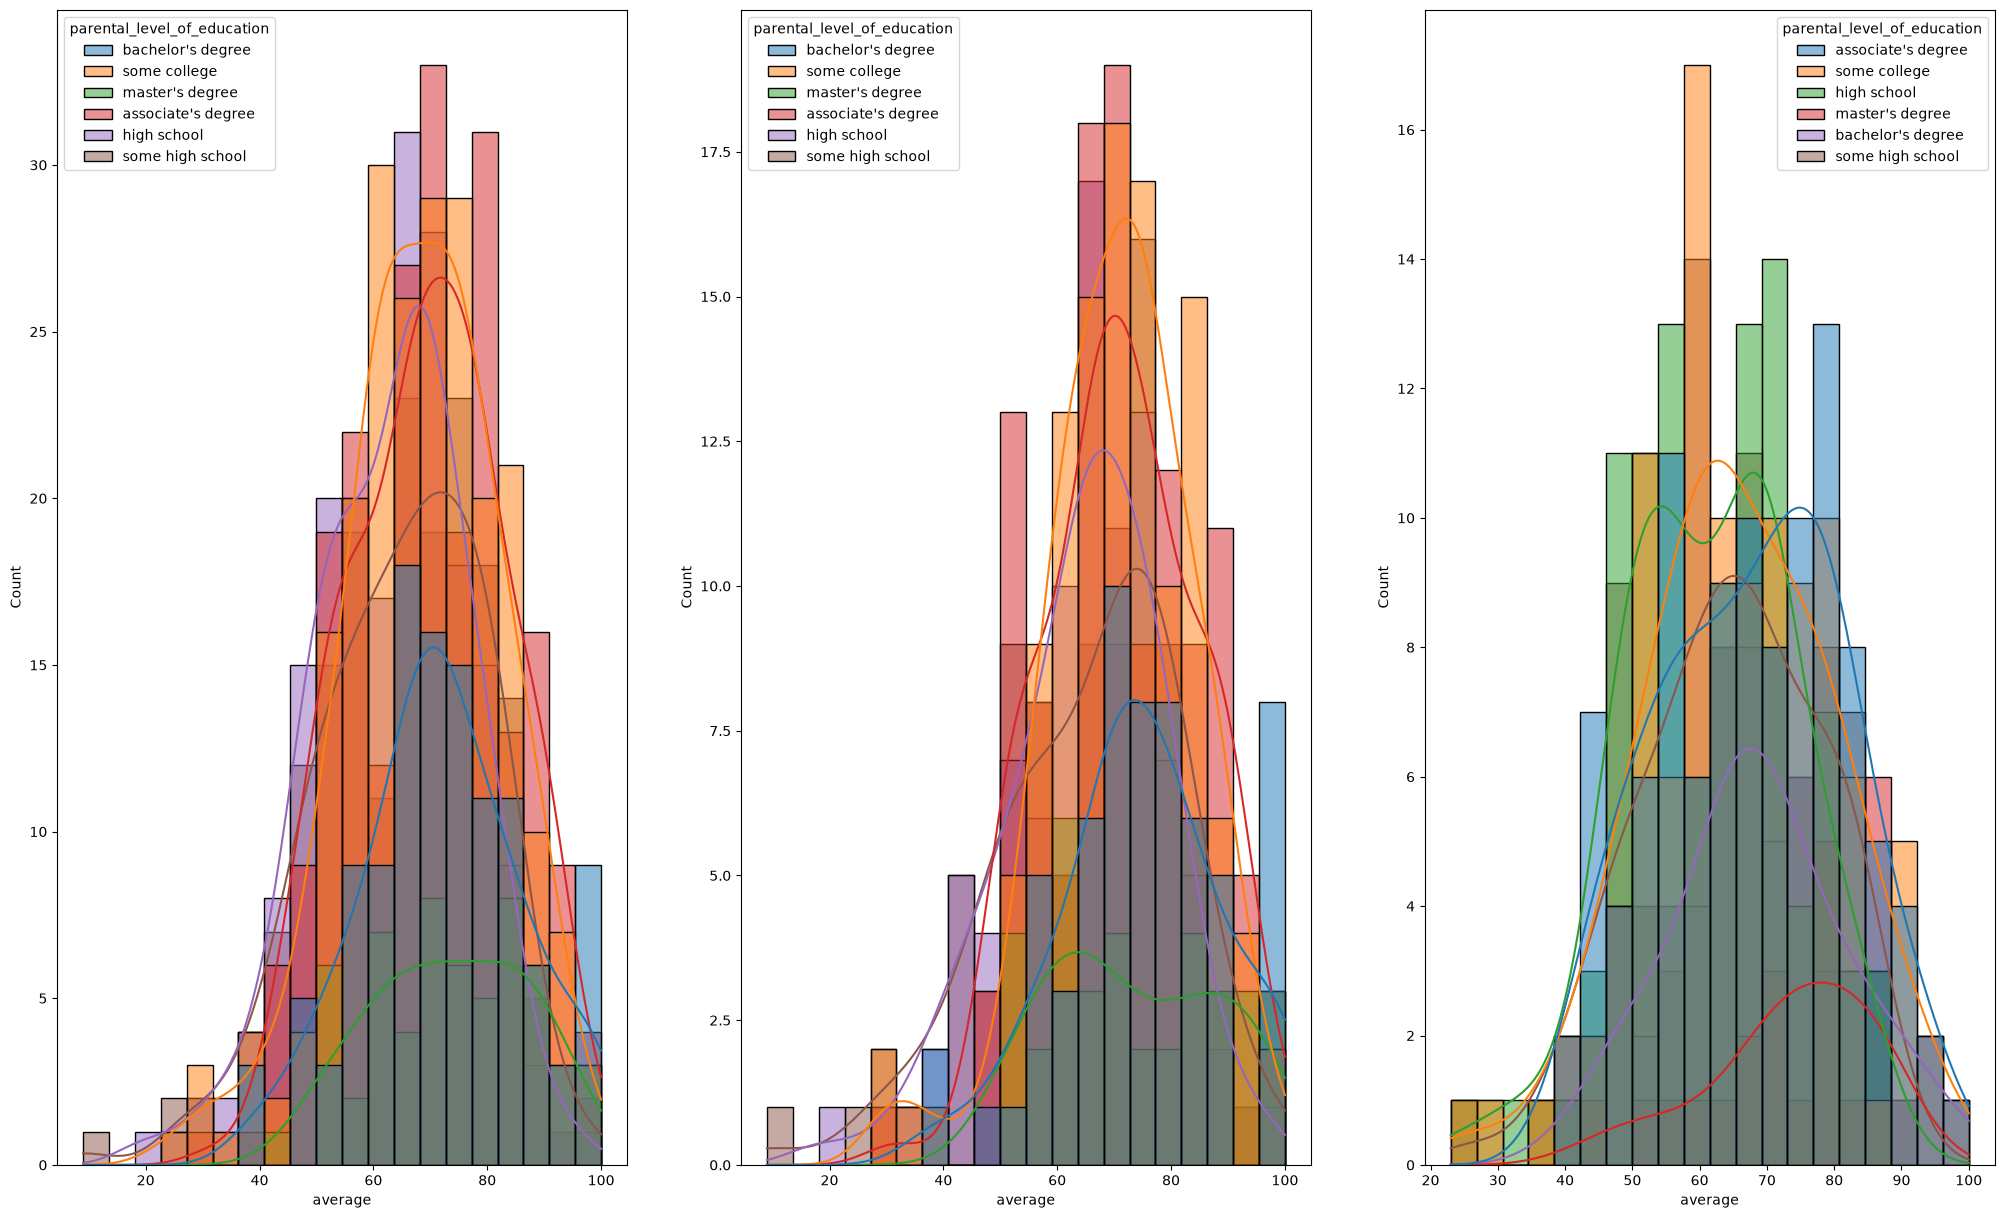

In [45]:
fig, axes = plt.subplots(1,3,figsize=(25,15))
plt.subplot(131)
sns.histplot(data=df,x='average',bins=20,kde=True,hue='parental_level_of_education')
plt.subplot(132)
sns.histplot(data=df[df['gender']=='female'],x='average',bins=20,kde=True,hue='parental_level_of_education')
plt.subplot(133)
sns.histplot(data=df[df['gender']=='male'],x='average',bins=20,kde=True,hue='parental_level_of_education')
plt.show()

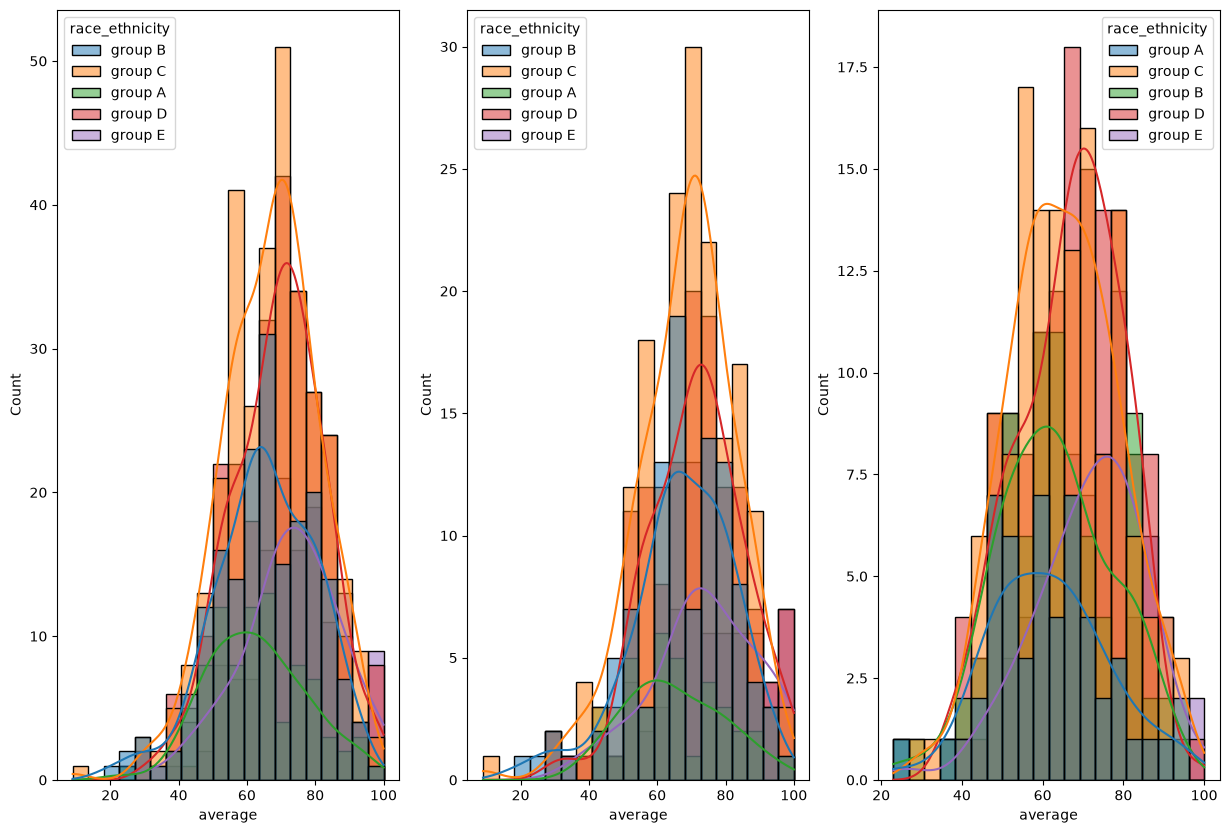

In [48]:
fig, axes = plt.subplots(1,3,figsize=(15,10))
plt.subplot(131)
sns.histplot(data=df,x='average',bins=20,kde=True,hue='race_ethnicity')
plt.subplot(132)
sns.histplot(data=df[df['gender']=='female'],x='average',bins=20,kde=True,hue='race_ethnicity')
plt.subplot(133)
sns.histplot(data=df[df['gender']=='male'],x='average',bins=20,kde=True,hue='race_ethnicity')
plt.show()

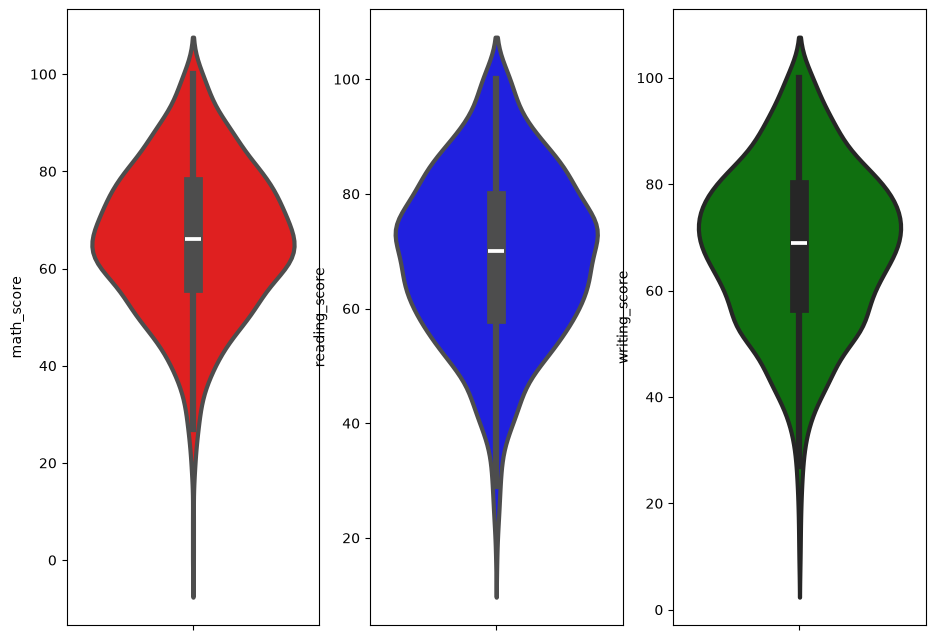

In [50]:
plt.figure(figsize=(15, 8))
plt.subplot(1,4,1)
sns.violinplot(data=df,y='math_score',color='red',linewidth=3)
plt.subplot(1,4,2)
sns.violinplot(data=df,y='reading_score',color='blue',linewidth=3)
plt.subplot(1,4,3)
sns.violinplot(data=df,y='writing_score',color='green',linewidth=3)
plt.show()

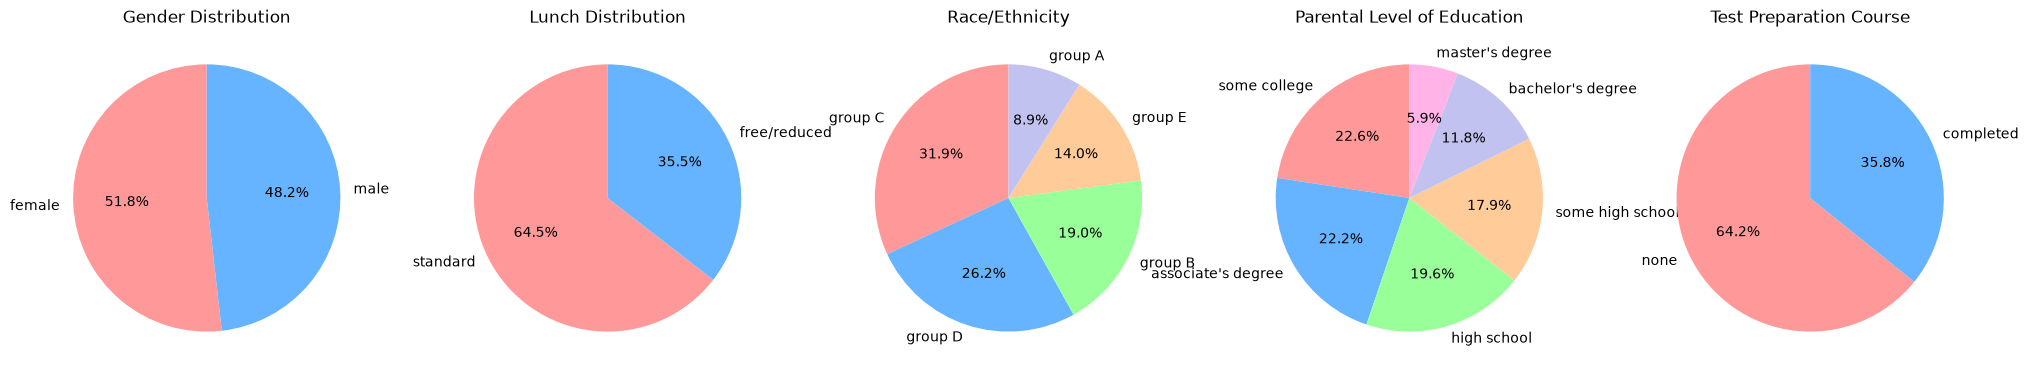

In [59]:
plt.rcParams['figure.figsize'] = (25, 15)
plt.subplot(1,5,1)
size=df['gender'].value_counts()
labels = df['gender'].value_counts().index
colors = ['#ff9999','#66b3ff']

plt.pie(size, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
plt.title('Gender Distribution')
plt.axis('off')
plt.subplot(1,5,2) 
size=df['lunch'].value_counts()
labels = df['lunch'].value_counts().index
colors = ['#ff9999','#66b3ff']

plt.pie(size, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
plt.title('Lunch Distribution')  
plt.axis('off')
plt.subplot(1,5,3) 
size=df['race_ethnicity'].value_counts()
labels = df['race_ethnicity'].value_counts().index
colors = ['#ff9999','#66b3ff', '#99ff99','#ffcc99','#c2c2f0']

plt.pie(size, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
plt.title('Race/Ethnicity')  
plt.axis('off')

plt.subplot(1,5,4) 
size=df['parental_level_of_education'].value_counts()
labels = df['parental_level_of_education'].value_counts().index
colors = ['#ff9999','#66b3ff', '#99ff99','#ffcc99','#c2c2f0', '#ffb3e6']

plt.pie(size, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
plt.title('Parental Level of Education')  
plt.axis('off')
plt.subplot(1,5,5) 
size=df['test_preparation_course'].value_counts()
labels = df['test_preparation_course'].value_counts().index
colors = ['#ff9999','#66b3ff']

plt.pie(size, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
plt.title('Test Preparation Course')  
plt.axis('off')
plt.show()


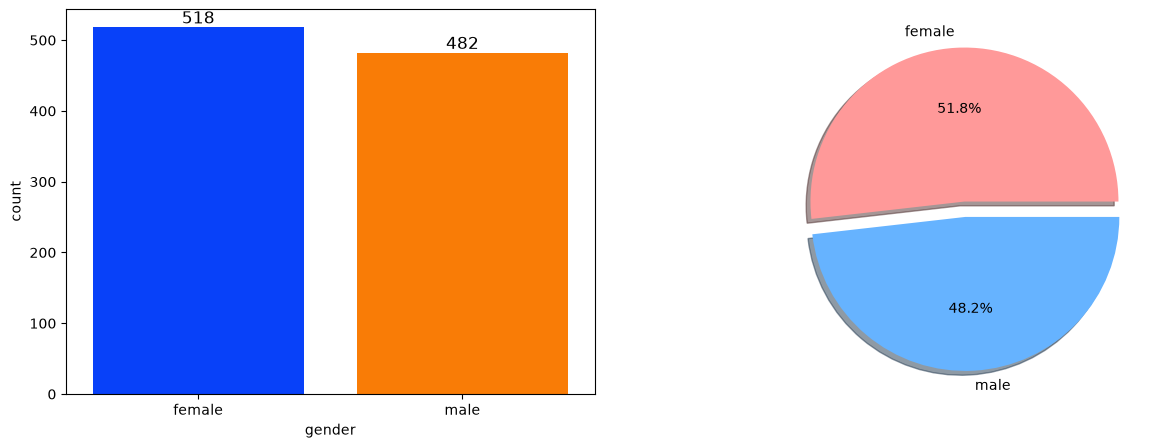

In [63]:
fig, axes = plt.subplots(1,2, figsize=(15,5))
sns.countplot(data=df,x='gender',palette='bright',ax=axes[0],saturation=0.95)
for c in axes[0].containers:
    axes[0].bar_label(c, label_type='edge', color='black', size=12)
plt.pie(x=df['gender'].value_counts(), labels=df['gender'].value_counts().index, autopct='%1.1f%%', explode=[0,0.1],shadow=True, colors=['#ff9999','#66b3ff'])
plt.show()

In [66]:
gender_group = df.groupby('gender').mean(numeric_only=True)
gender_group

,math_score,reading_score,writing_score,total_score,average
gender,,,,,
female,63.633205,72.608108,72.467181,208.708494,69.569498
male,68.728216,65.473029,63.311203,197.512448,65.837483


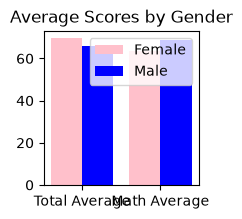

In [69]:
plt.figure(figsize=(2, 2))
X= ['Total Average', 'Math Average']

female_avg = [gender_group.loc['female','average'], gender_group.loc['female','math_score']]
male_avg = [gender_group.loc['male','average'], gender_group.loc['male','math_score']]

x_axis = np.arange(len(X))
plt.bar(x_axis - 0.2, female_avg, 0.4, label='Female', color='pink')
plt.bar(x_axis + 0.2, male_avg, 0.4, label='Male', color='blue')
plt.xticks(x_axis, X)
plt.title('Average Scores by Gender')
plt.legend()
plt.show()

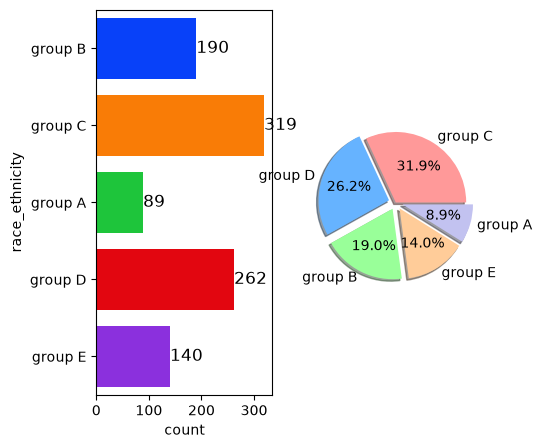

In [70]:
fig, axes = plt.subplots(1,2, figsize=(5,5))
sns.countplot(data=df['race_ethnicity'],palette='bright',ax=axes[0],saturation=0.95)
for c in axes[0].containers:
    axes[0].bar_label(c, label_type='edge', color='black', size=12)
plt.pie(x=df['race_ethnicity'].value_counts(), labels=df['race_ethnicity'].value_counts().index, autopct='%1.1f%%', explode=[0,0.1,0.1,0.1,0.1],shadow=True, colors=['#ff9999','#66b3ff', '#99ff99','#ffcc99','#c2c2f0'])
plt.show()

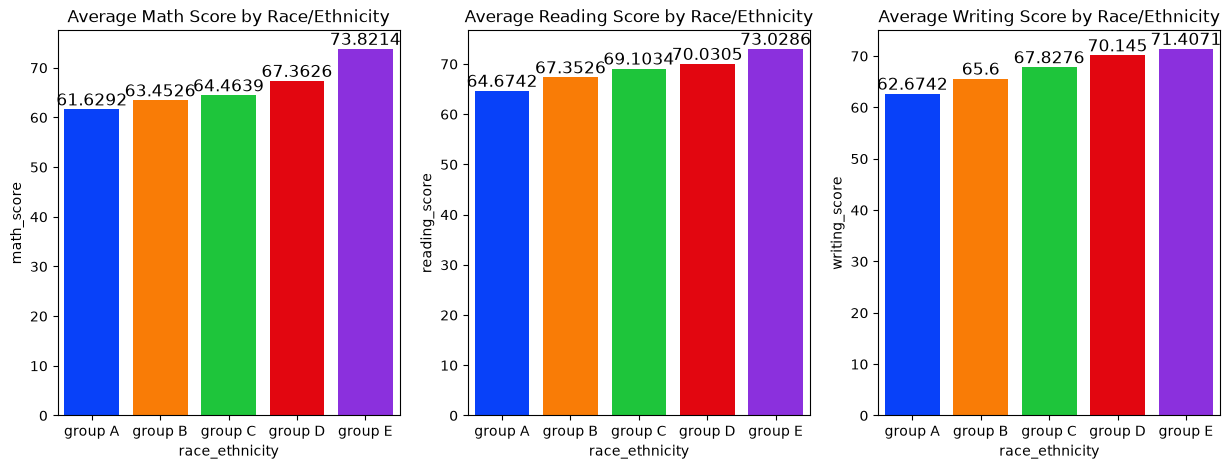

In [72]:
race_group = df.groupby('race_ethnicity').mean(numeric_only=True)
fig, axes = plt.subplots(1,3, figsize=(15,5))
sns.barplot(x=race_group.index,y=race_group['math_score'],palette='bright',ax=axes[0],saturation=0.95)
axes[0].set_title('Average Math Score by Race/Ethnicity')
for c in axes[0].containers:
    axes[0].bar_label(c, label_type='edge', color='black', size=12)

sns.barplot(x=race_group.index,y=race_group['reading_score'],palette='bright',ax=axes[1],saturation=0.95)
axes[1].set_title('Average Reading Score by Race/Ethnicity')
for c in axes[1].containers:
    axes[1].bar_label(c, label_type='edge', color='black', size=12)

sns.barplot(x=race_group.index,y=race_group['writing_score'],palette='bright',ax=axes[2],saturation=0.95)
axes[2].set_title('Average Writing Score by Race/Ethnicity')
for c in axes[2].containers:
    axes[2].bar_label(c, label_type='edge', color='black', size=12)

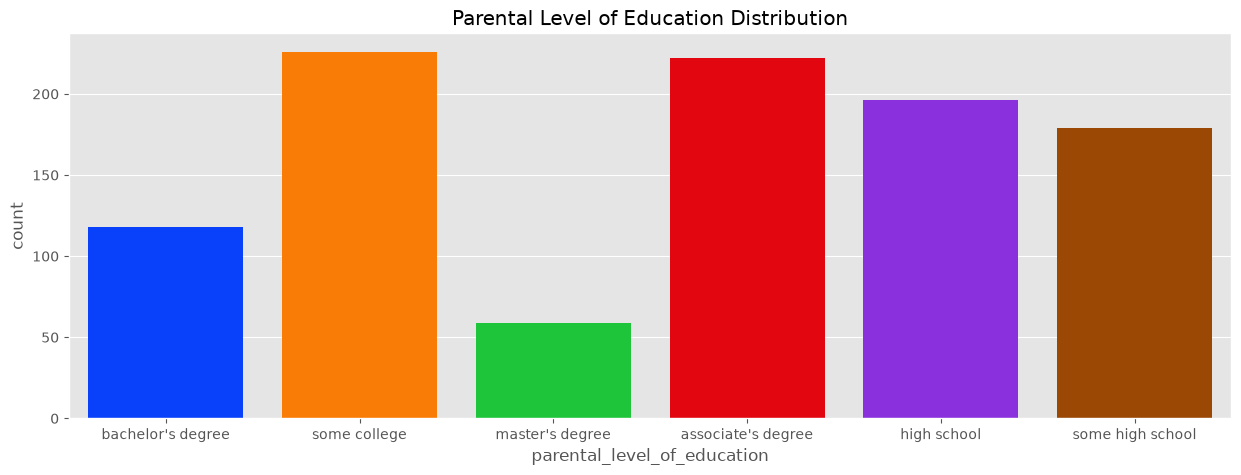

In [75]:
plt.rcParams['figure.figsize'] = (15,5)
plt.style.use('ggplot')
sns.countplot(data=df,x='parental_level_of_education',palette='bright',saturation=0.95)
plt.title('Parental Level of Education Distribution')
plt.show()

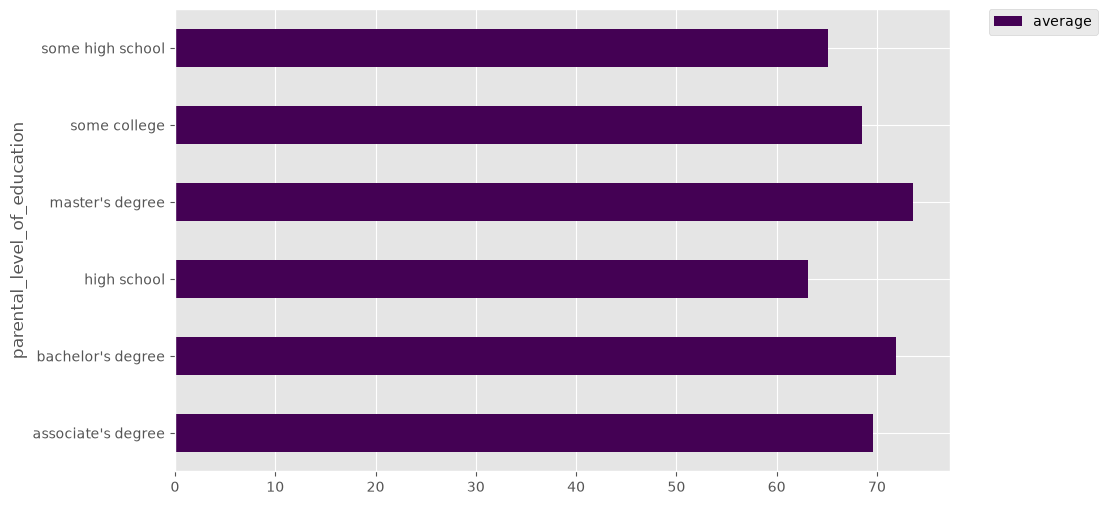

In [77]:
df.groupby('parental_level_of_education')['average'].agg('mean').plot(kind='barh', figsize=(10, 6), colormap='viridis')
plt.legend(bbox_to_anchor=(1.05,1),loc=2, borderaxespad=0.)
plt.show()

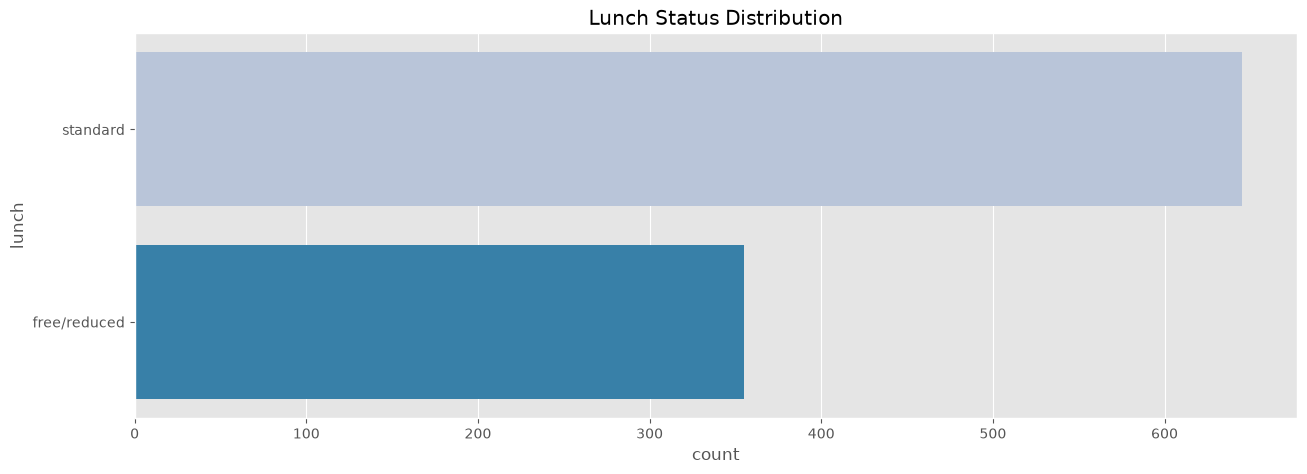

In [81]:
plt.rcParams['figure.figsize'] = (15,5)
plt.style.use('ggplot')
sns.countplot(data=df['lunch'],palette='PuBu')
plt.title('Lunch Status Distribution')
plt.show()

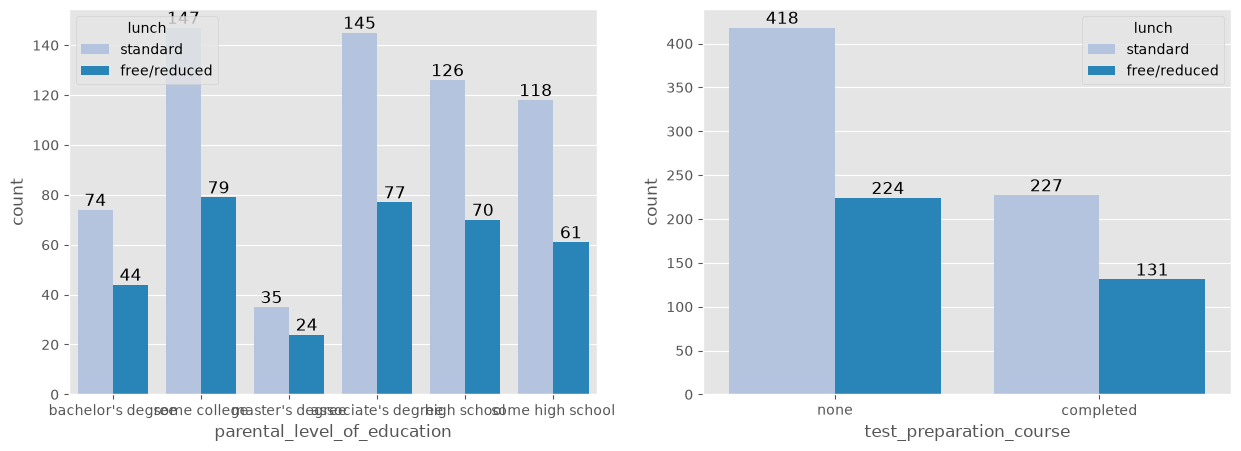

In [82]:
fig, axes = plt.subplots(1,2, figsize=(15,5))
sns.countplot(data=df,x=df['parental_level_of_education'],hue=df['lunch'],palette='PuBu',ax=axes[0],saturation=0.95)
for c in axes[0].containers:
    axes[0].bar_label(c,label_type='edge', color='black', size=12)
sns.countplot(data=df,x=df['test_preparation_course'],hue=df['lunch'],palette='PuBu',ax=axes[1],saturation=0.95)
for c in axes[1].containers:
    axes[1].bar_label(c,label_type='edge', color='black', size=12)

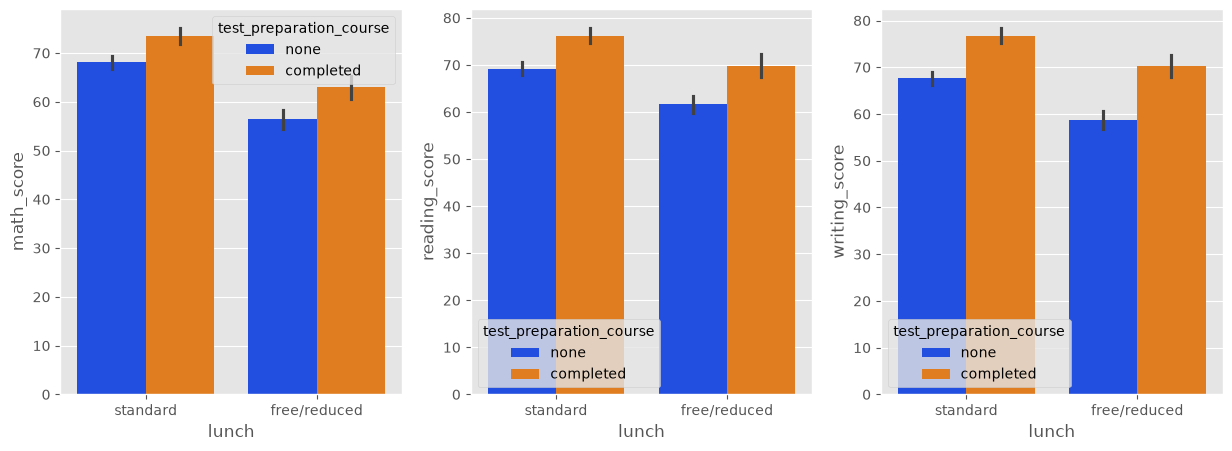

In [83]:
fig,axes =plt.subplots(1,3, figsize=(15,5))
plt.subplot(131)
sns.barplot(data=df,x='lunch',y='math_score',hue='test_preparation_course',palette='bright')
plt.subplot(132)
sns.barplot(data=df,x='lunch',y='reading_score',hue='test_preparation_course',palette='bright')
plt.subplot(133)
sns.barplot(data=df,x='lunch',y='writing_score',hue='test_preparation_course',palette='bright')
plt.show()

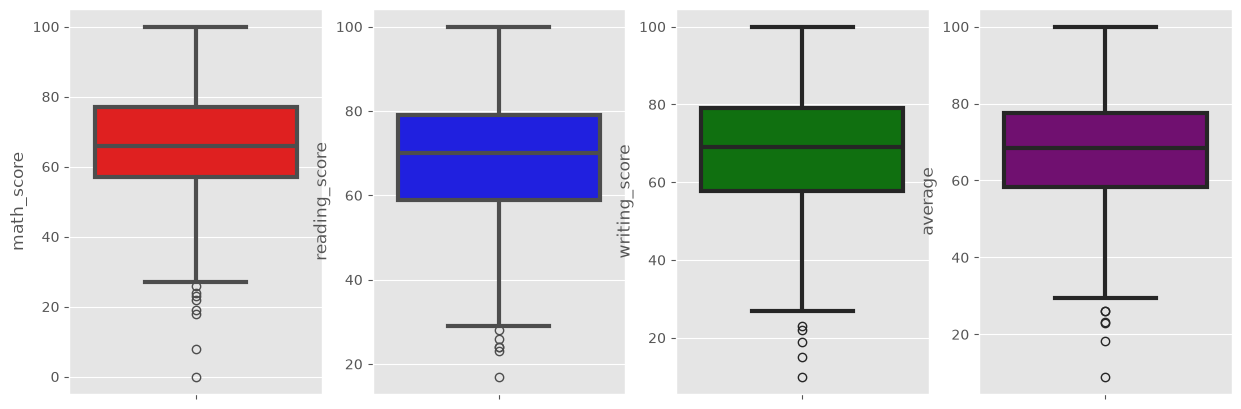

In [84]:
plt.subplots(1,4, figsize=(15,5))
plt.subplot(141)
sns.boxplot(df['math_score'],color='red',linewidth=3)
plt.subplot(142)
sns.boxplot(df['reading_score'],color='blue',linewidth=3)
plt.subplot(143)
sns.boxplot(df['writing_score'],color='green',linewidth=3)
plt.subplot(144)
sns.boxplot(df['average'],color='purple',linewidth=3)
plt.show()

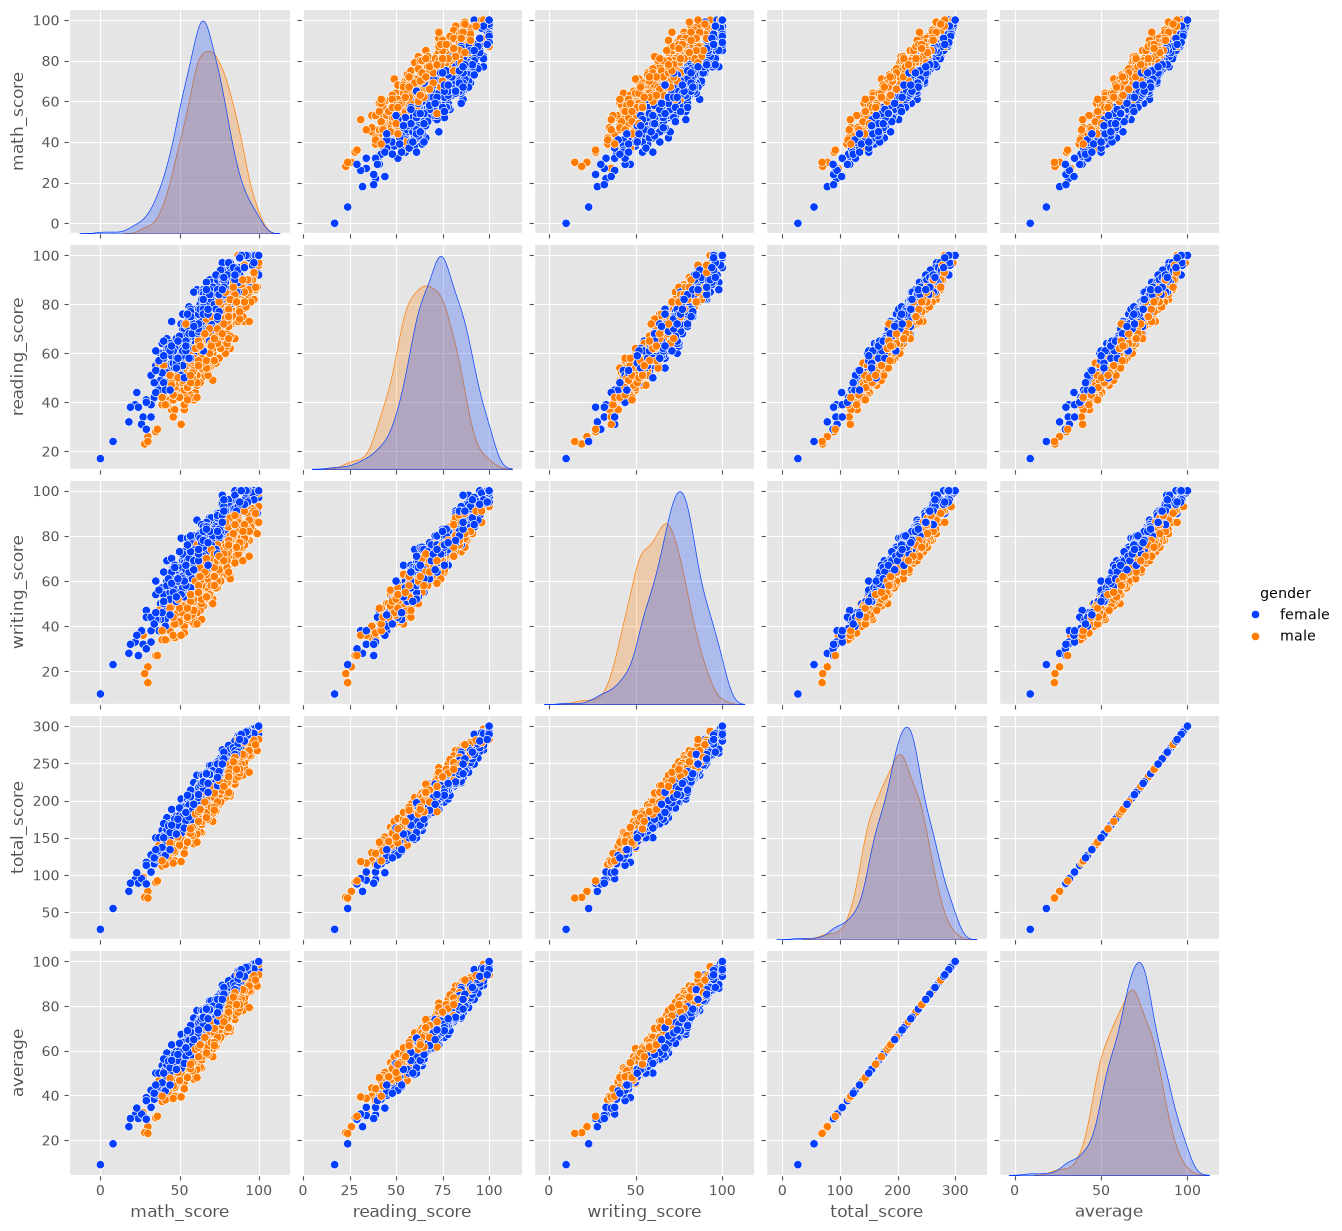

In [85]:
sns.pairplot(df,hue='gender',palette='bright')